# Protein Supply Divergence → U.S. Broiler Production
**Retrospective USDA/plotnine monthly industry-production falsification · 2026-10-28 · NAICS 311615 · NOT PIT / NOT EQUITY ALPHA**

This notebook is a self-contained analytical narrative, not a wrapper that merely imports results. It executes the full study, independently inspects the frozen source and release cutoffs, computes additional diagnostics and displays saved output figures. The primary result is a negative factor test; all numbers below are computed by the accompanying Python module and checked in this notebook.

## 01. Abstract

**Research question:** Does a two-month-stale beef/pork-versus-turkey production-growth divergence improve three-month-ahead U.S. broiler-production YoY forecasts over expanding-window historical mean, broiler persistence, momentum, AR Ridge and a multivariate supply control? The dependent variable is physical output, **not** revenue, EPS, security returns or a tradable total-return alpha. The empirical source is a frozen `plotnine.data.meat` file derived from USDA ERS and observed through December 2023; its original release vintages are **UNKNOWN**. We treat this as retrospective falsification only.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, SVG
import run_analysis as ra
pd.set_option('display.max_columns', 12)
M = ra.run_all()
print('STUDY STATUS:', M['status'])
print('Empirical window:', M['data_start'], 'to', M['data_end'])
print('OOS:', M['oos_start'], 'to', M['oos_end'], '| n =', M['oos_n'])

{
  "raw_n": 960,
  "panel_n": 748,
  "oos_n": 165,
  "observed_rmse_gain_log_pp": -0.024796332384697806,
  "placebo_exploratory_tail_fraction": 0.8431568431568431,
  "bootstrap_gain_ci_95": [
    -0.07869146697147278,
    0.02573495468354355
  ],
  "weight_positive_gain_fraction": 0.0
}
          model  n_oos  rmse_log_pp  mae_log_pp  bias_log_pp
       ar_ridge    165     4.730863    3.720950     1.782271
  macro_control    165     4.750559    3.759174     1.657178
      augmented    165     4.775356    3.775693     1.737412
    factor_only    165     4.853096    3.811340     2.071261
historical_mean    165     4.887904    3.852647     2.258807
    persistence    165     5.910236    4.778254     0.146698
       momentum    165     8.251212    6.607441     0.264547
STUDY STATUS: REPRODUCED RETROSPECTIVE POULTRY PRODUCTION MACRO PILOT - NOT PIT / NOT EQUITY ALPHA
Empirical window: 1944-01-01 to 2023-12-01
OOS: 2010-01-01 to 2023-09-01 | n = 165


The release gate is a **reproduced macro pilot** only if the run, source QA, tests and notebook all succeed. Statistical significance or an investable claim is never inferred from the number of charts, cells or Monte Carlo draws.

In [2]:
assert M['raw_n']==960 and M['broiler_n']==768
assert M['pit_verified'] is False and M['equity_alpha_established'] is False
assert M['oos_n']>100
print('Primary effect (control minus augmented RMSE):', round(M['observed_rmse_gain_log_pp'],6),'log-pp')

Primary effect (control minus augmented RMSE): -0.024796 log-pp


## 02. Research Design & Hypotheses

**H1 (mechanism):** an imbalance in red-meat supply growth relative to turkey supply may lead broiler output through protein substitution, capacity allocation and retailer procurement; its direction is uncertain because broiler production itself is supply constrained. **H2 (incremental forecast):** the predeclared nonlinear divergence improves three-month-ahead broiler YoY output growth beyond broiler lags and red-meat growth. **H3 (robustness):** gains persist under twelve-month block reorders, block bootstrap, component removals, beef/pork weight changes, alternative publication buffers and horizons, and across regimes. **Null:** the incremental RMSE gain is zero or negative. Failure means no predictive claim.

In [3]:
print('Frozen preregistered configuration:')
print({'horizon_months':ra.HORIZON,'lag_months':ra.LAG,'alpha':ra.ALPHA,
       'oos_start':ra.OOS_START,'min_train':ra.MIN_TRAIN,'seed':ra.SEED})
print('Control features:',ra.CONTROL)
print('Candidate: fixed tanh([0.5*beef_yoy + 0.5*pork_yoy - turkey_yoy]/20)')

Frozen preregistered configuration:
{'horizon_months': 3, 'lag_months': 2, 'alpha': 10.0, 'oos_start': '2010-01-01', 'min_train': 240, 'seed': 20261028}
Control features: ['broiler_yoy_lag2', 'broiler_yoy_lag5', 'broiler_mom3_lag2', 'red_yoy_lag2']
Candidate: fixed tanh([0.5*beef_yoy + 0.5*pork_yoy - turkey_yoy]/20)


## 03. Industry Context

Broiler production is measured in **millions of pounds per month**, not dollars. USDA ERS documents federally inspected broiler and turkey production alongside beef and pork; the red-meat and poultry weight bases differ, so the signal uses **within-category log growth rates** rather than raw weight ratios. USDA NASS reports that poultry slaughter is released around the 25th of the following month, with prior-month revisions. The U.S. broiler sector has structural trends and pandemic disruptions that must not be confused with forecasting skill. See source register S02–S03.

In [4]:
raw=ra.load_raw()
print('2023 broiler production, million pounds:',round(M['broiler_production_2023_million_lb'],1))
print('2019-2023 broiler production change, %:',round(M['broiler_production_2019_2023_growth_pct'],3))
display(raw.tail(6))

2023 broiler production, million pounds: 46383.4
2019-2023 broiler production change, %: 5.645


,date,beef,veal,pork,lamb_and_mutton,broilers,other_chicken,turkey
954,2023-07-01,2107.9,3.8,2006.8,9.5,3717.2,50.9,433.5
955,2023-08-01,2363.5,4.2,2295.0,10.5,4156.7,51.1,489.2
956,2023-09-01,2149.4,3.6,2186.2,10.2,3805.5,48.4,431.2
957,2023-10-01,2340.9,4.2,2418.5,11.3,4177.3,50.6,500.3
958,2023-11-01,2280.9,4.3,2388.2,11.2,3817.3,44.5,449.2
959,2023-12-01,2189.9,3.9,2342.0,10.7,3615.6,41.5,393.0


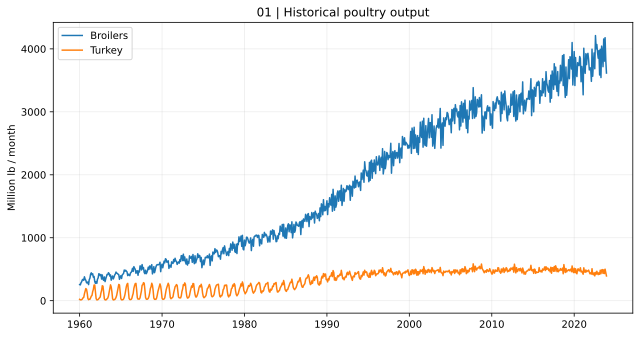

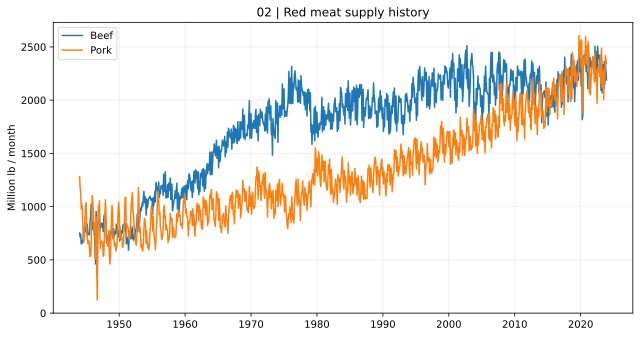

In [5]:
display(SVG(filename=str(ra.FIGURES/'01_poultry_output.svg')))
display(SVG(filename=str(ra.FIGURES/'02_red_meat_output.svg')))

The observed industry output growth is a **volume proxy**; it cannot establish margins, prices, company revenue or investment returns. Production substitution is a plausible hypothesis, not a causal identification strategy.

## 04. Data & Source Integrity

Source grade **A** means an official USDA release/document or SEC filing, **B** a redistributed frozen empirical copy with a named official origin, **C** an unverified secondary estimate (none enters this model). The only empirical observations come from the locally frozen 960-row plotnine 0.15.3 `meat.csv` (SHA-256 in the summary). The latest USDA page is not asserted to be the same vintage. Historical first-publication timestamps, revisions and some original source metadata are explicitly **UNKNOWN**.

In [6]:
reg=pd.read_csv(ra.HERE/'data/source_register.csv')
display(reg[['id','grade','publisher','source','release_date','observation_start','observation_end','usage']])
print('SHA-256 frozen input:',hashlib.sha256(ra.RAW.read_bytes()).hexdigest())
assert hashlib.sha256(ra.RAW.read_bytes()).hexdigest()==M['raw_sha256']

,id,grade,publisher,source,release_date,observation_start,observation_end,usage
0,S01,B,plotnine project / bundled data,plotnine.data.meat,UNKNOWN (bundled snapshot provenance not dated),1944-01,2023-12,Only empirical frozen input
1,S02,A,USDA Economic Research Service,Livestock and Meat Domestic Data documentation,2026-09-29 (documentation updated),1921 (documented production history; varies by...,ongoing,Definitions and industry context
2,S03,A,USDA National Agricultural Statistics Service,Poultry Slaughter survey guide,UNKNOWN (web page undated),UNKNOWN,ongoing,Conservative 2-month formation buffer
3,S04,A,U.S. Securities and Exchange Commission,Tyson Foods FY2023 Form 10-K,2023-11-13,2023-09-30,2023-09-30,Descriptive company transmission map only
4,S05,A,U.S. Securities and Exchange Commission,Pilgrims Pride FY2023 Form 10-K,2024-02-27,2023-12-31,2023-12-31,Descriptive company transmission map only
5,S06,A,USDA Economic Research Service,Livestock and Meat Domestic Data landing page,2026-10-27 (page updated),historical,ongoing,Next-stage historical vintage acquisition plan


SHA-256 frozen input: b587c1e758ae43d87fe86fac0efc73da40aaeaf4046eba370f70fced554564a5


In [7]:
qa=pd.DataFrame({'nonmissing':raw.notna().sum(), 'missing':raw.isna().sum()})
display(qa)
assert raw.date.is_unique and raw.date.diff().dropna().dt.days.between(28,31).all()
print('Data QA: unique monthly dates, no gaps, positive observed production; broilers/turkey start 1960.')

,nonmissing,missing
date,960,0
beef,960,0
veal,960,0
pork,960,0
lamb_and_mutton,960,0
broilers,768,192
other_chicken,276,684
turkey,768,192


Data QA: unique monthly dates, no gaps, positive observed production; broilers/turkey start 1960.


## 05. Point-in-Time Availability

At formation month `t`, each signal/control is computed only from data with **observation month ≤ t−2**. This conservative two-month proxy buffer is motivated by USDA's next-month reporting and revision practice. **It is not archival point-in-time verification**: a 2023-ending redistributed file may embed revisions unavailable in 1970, 2000 or 2010. Training labels are admitted only if their target month plus two months is ≤ the forecast origin; thus the three-month forecast uses a five-month minimum origin-to-training-label gap.

In [8]:
panel=ra.make_panel(raw)
pred=ra.walkforward(panel)
print('Panel observations:',len(panel),'| OOS:',len(pred))
print('First OOS formation:',pred.date.min(),'last:',pred.date.max())
print('Min training labels:',pred.n_train.min(),'Max:',pred.n_train.max())
assert (pred.max_training_label_available<=pred.date).all()
display(pred[['date','target_date','max_training_target_date','max_training_label_available','n_train']].head())

Panel observations: 748 | OOS: 165
First OOS formation: 2010-01-01 00:00:00 last: 2023-09-01 00:00:00
Min training labels: 579 Max: 743


,date,target_date,max_training_target_date,max_training_label_available,n_train
0,2010-01-01,2010-04-01,2009-11-01,2010-01-01,579
1,2010-02-01,2010-05-01,2009-12-01,2010-02-01,580
2,2010-03-01,2010-06-01,2010-01-01,2010-03-01,581
3,2010-04-01,2010-07-01,2010-02-01,2010-04-01,582
4,2010-05-01,2010-08-01,2010-03-01,2010-05-01,583


In [9]:
i=panel.index[150]
t=panel.loc[i,'date']
changed=raw.copy();changed.loc[changed.date==t,'beef']*=20
assert np.isclose(ra.make_panel(changed).loc[i,'factor'],panel.loc[i,'factor'])
print('Causality check: altering formation-month beef cannot alter factor at that origin.')

Causality check: altering formation-month beef cannot alter factor at that origin.


## 06. Factor Construction

For category `c`, let `g(c,s)=100 log(P(c,s)/P(c,s−12))`, in log-percentage points. The **fixed, non-fitted** factor is `F(t)=tanh([0.5 g(beef,t−2)+0.5 g(pork,t−2)−g(turkey,t−2)]/20)`. The hyperbolic tangent bounds extreme historical growth rates without using full-sample mean/variance. Beef/pork weights 0.5/0.5 and divisor 20 are predeclared, not optimized on outcomes. A high value is a red-meat production premium over turkey; the sign of the subsequent broiler response is empirical.

In [10]:
v=panel[['date','beef_yoy_lag2','pork_yoy_lag2','turkey_yoy_lag2','factor_raw','factor']].head(6)
display(v)
assert np.allclose(panel.factor,np.tanh(panel.factor_raw/20))
print('Factor quantiles:');display(panel.factor.quantile([0,.05,.25,.5,.75,.95,1]).to_frame('factor'))

,date,beef_yoy_lag2,pork_yoy_lag2,turkey_yoy_lag2,factor_raw,factor
0,1961-06-01,6.447989,-10.048840,32.404972,-34.205397,-0.936681
1,1961-07-01,9.440219,1.969429,50.267441,-44.562617,-0.977055
2,1961-08-01,6.669137,0.234467,45.907456,-42.455654,-0.971750
3,1961-09-01,4.772777,-0.138217,45.740046,-43.422766,-0.974320
4,1961-10-01,2.791581,-0.945634,27.110711,-26.187737,-0.864120
5,1961-11-01,-2.417272,-0.831853,18.165288,-19.789851,-0.757146


Factor quantiles:


,factor
0.00,-0.989274
0.05,-0.789527
0.25,-0.352030
0.50,-0.053742
0.75,0.193529
0.95,0.570032
1.00,0.993770


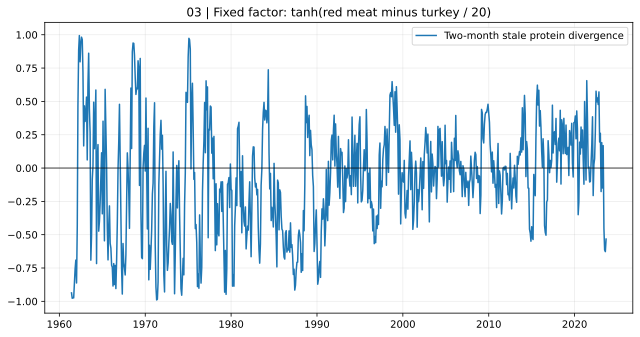

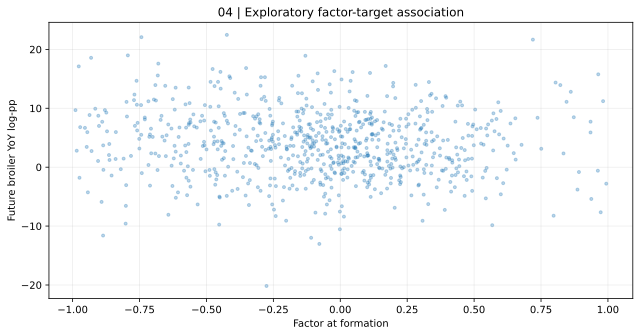

In [11]:
display(SVG(filename=str(ra.FIGURES/'03_factor_history.svg')))
display(SVG(filename=str(ra.FIGURES/'04_scatter.svg')))

## 07. Exposure & Transmission

The 2023 filings of Tyson Foods and Pilgrim's Pride support **qualitative** links between public poultry producers and the broiler market. Tyson also operates Beef, Pork and Prepared Foods; Pilgrim's Pride has non-U.S. operations. **No numerical corporate exposure weights are invented.** These 2023 filings are not retroactively assigned to 1960–2022, and the companies do not enter the numerical forecast or constitute a backtested historical investable universe.

In [12]:
exp=pd.read_csv(ra.HERE/'data/company_exposure_map.csv')
display(exp[['company','ticker','filing_date','business_exposure','historical_exposure_weight','used_in_quant_model']])
assert (exp.used_in_quant_model=='NO').all()

,company,ticker,filing_date,business_exposure,historical_exposure_weight,used_in_quant_model
0,Tyson Foods,TSN,2023-11-13,Chicken segment and separate Beef and Pork seg...,UNKNOWN / not estimated,NO
1,Pilgrim's Pride,PPC,2024-02-27,"Poultry/chicken operations in U.S., Europe and...",UNKNOWN / not estimated,NO


## 08. Outcomes & Baselines

The **only** quantitative target is `Y(t+3)=100 log(B(t+3)/B(t−9))`, where `B` is broiler output. Expanding training begins once ≥240 complete, published-proxy labels exist. Baselines are historical target mean; last available broiler YoY persistence; extrapolated recent broiler momentum; AR Ridge; and multivariate Ridge with lagged broiler growth, lagged three-month broiler momentum and red-meat growth. The challenger adds `F(t)` to that same multivariate control. Ridge alpha=10 is fixed; all feature means and scales are fitted on the training fold only.

In [13]:
scores=ra.scorecard(pred)
display(scores)
print('Primary RMSE improvement:',ra.rmse(pred.target,pred.macro_control)-ra.rmse(pred.target,pred.augmented))
assert np.isclose(scores.loc[scores.model=='augmented','rmse_log_pp'].iloc[0],ra.rmse(pred.target,pred.augmented))

,model,n_oos,rmse_log_pp,mae_log_pp,bias_log_pp
3,ar_ridge,165,4.730863,3.720950,1.782271
4,macro_control,165,4.750559,3.759174,1.657178
6,augmented,165,4.775356,3.775693,1.737412
5,factor_only,165,4.853096,3.811340,2.071261
0,historical_mean,165,4.887904,3.852647,2.258807
1,persistence,165,5.910236,4.778254,0.146698
2,momentum,165,8.251212,6.607441,0.264547


Primary RMSE improvement: -0.024796332384697806


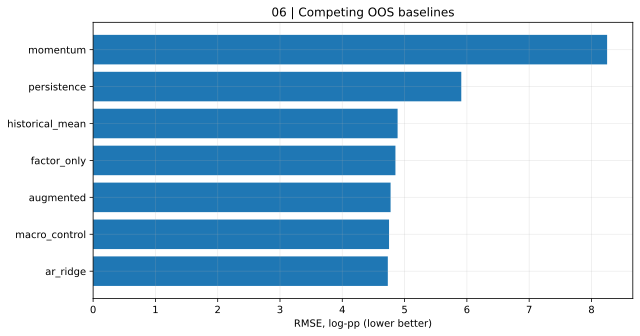

In [14]:
display(SVG(filename=str(ra.FIGURES/'06_rmse_scorecard.svg')))

## 09. Empirical Findings

All seven models use the same **165** OOS forecast origins, 2010-01 through 2023-09. The primary comparison is the paired difference between macro-control and augmented RMSE, not the absolute fit of the augmented model. OOS error magnitude is measured in log-percentage points. The cross-time Spearman association below is descriptive and is **not** a cross-sectional security Rank IC.

In [15]:
print('Spearman across formation months (descriptive, not equity IC):',round(M['factor_target_full_panel_spearman'],4))
print('Augmented - control forecast error summary:')
err=pd.DataFrame({'date':pred.date,'control_error':pred.target-pred.macro_control,'augmented_error':pred.target-pred.augmented})
display(err[['control_error','augmented_error']].describe())

Spearman across formation months (descriptive, not equity IC): -0.0937
Augmented - control forecast error summary:


,control_error,augmented_error
count,165.000000,165.000000
mean,-1.657178,-1.737412
std,4.465696,4.461621
min,-14.465777,-14.504413
25%,-4.722902,-4.912135
50%,-1.054473,-1.271946
75%,1.565898,1.529990
max,8.724492,8.441504


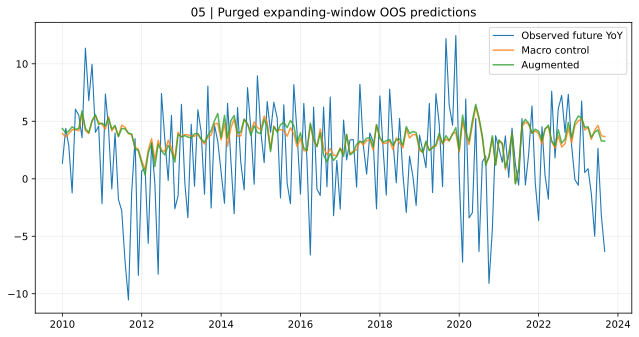

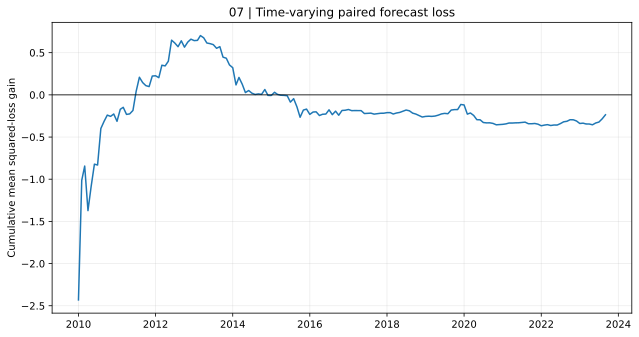

In [16]:
display(SVG(filename=str(ra.FIGURES/'05_oos_predictions.svg')))
display(SVG(filename=str(ra.FIGURES/'07_loss_gain.svg')))

In [17]:
fig,ax=plt.subplots(figsize=(8,3.5))
ax.scatter(pred.macro_control,pred.target,s=18,alpha=.55,label='Control')
ax.scatter(pred.augmented,pred.target,s=18,alpha=.55,label='Augmented')
lo=min(pred.target.min(),pred.macro_control.min(),pred.augmented.min());hi=max(pred.target.max(),pred.macro_control.max(),pred.augmented.max())
ax.plot([lo,hi],[lo,hi],'k--',lw=1)
ax.set(xlabel='Forecast YoY log-pp',ylabel='Realized YoY log-pp',title='Computed calibration: actual versus forecasts');ax.legend();plt.show()

/tmp/ipykernel_876/3840377278.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ax.set(xlabel='Forecast YoY log-pp',ylabel='Realized YoY log-pp',title='Computed calibration: actual versus forecasts');ax.legend();plt.show()


## 10. Robustness & Placebos

The **1,000-refit exploratory null** reorders the candidate factor in contiguous 12-month blocks while holding controls and target fixed, then repeats the entire expanding OOS forecast. Because block reordering does not preserve every conditional dependence structure, its tail fraction is **not** an exact p-value. The **2,000-draw paired moving-block bootstrap** resamples 12-month OOS error blocks to obtain a confidence interval for the RMSE gain. The **1,000-draw exposure perturbation** samples beef weight uniformly from [0.2,0.8] and assigns the remainder to pork, keeping the turkey subtraction fixed.

In [18]:
null=pd.read_csv(ra.RESULTS/'placebo_draws.csv').gain_log_pp
boot=pd.read_csv(ra.RESULTS/'bootstrap_draws.csv').gain_log_pp
weights=pd.read_csv(ra.RESULTS/'weight_perturbations.csv')
print('Null draws:',len(null),'exploratory tail fraction:',M['placebo_exploratory_tail_fraction'])
print('Bootstrap draws:',len(boot),'95% interval:',M['bootstrap_gain_ci_95'])
print('Weight draws:',len(weights),'positive fraction:',M['weight_positive_gain_fraction'])
assert len(null)>=1000 and len(boot)>=2000 and len(weights)>=1000

Null draws: 1000 exploratory tail fraction: 0.8431568431568431
Bootstrap draws: 2000 95% interval: [-0.07869146697147278, 0.02573495468354355]
Weight draws: 1000 positive fraction: 0.0


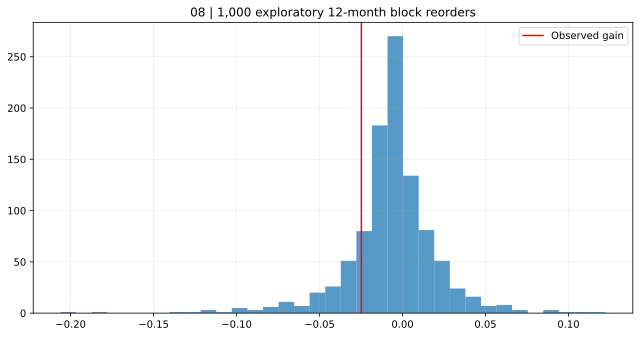

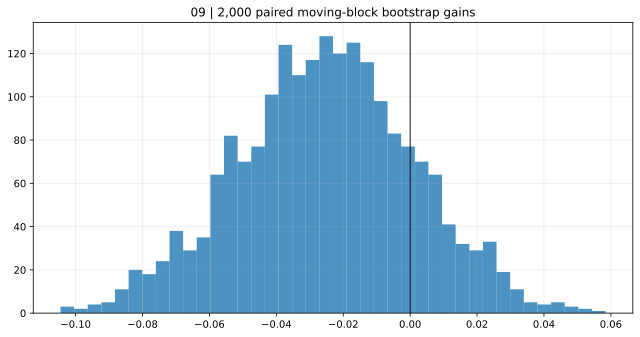

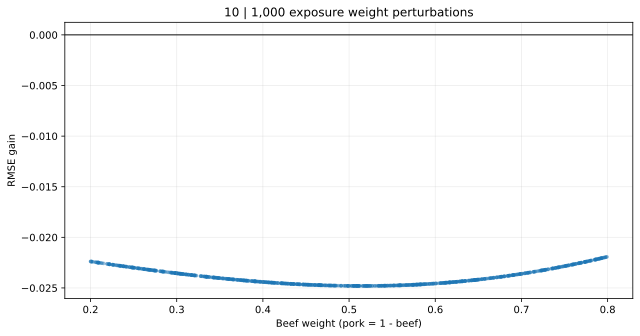

In [19]:
display(SVG(filename=str(ra.FIGURES/'08_placebo.svg')))
display(SVG(filename=str(ra.FIGURES/'09_bootstrap.svg')))
display(SVG(filename=str(ra.FIGURES/'10_exposure_weights.svg')))

**Leave-one-company-out is not applicable** because no company-level observations enter the estimation. Instead, we perform leave-one-input-component-out ablations (beef-only, pork-only, red-meat-only and turkey-only). A factor sign flip under symmetric Ridge is an algebraic invariance check, **not** independent evidence. The red-meat-only result is post hoc and cannot rescue the predeclared hypothesis without multiple-testing control.

,case,n_oos,gain_log_pp
0,base_equal_beef_pork_minus_turkey,165,-0.024796
1,beef_only_minus_turkey,165,-0.016728
2,pork_only_minus_turkey,165,-0.019564
3,red_meat_only,165,0.003233
4,negative_turkey_only,165,-0.029263
5,factor_sign_flipped,165,-0.024796


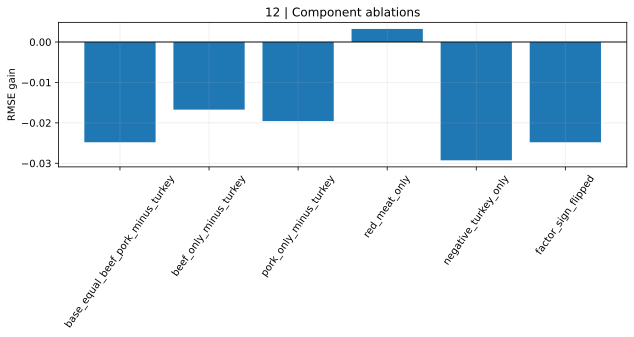

In [20]:
abl=pd.read_csv(ra.RESULTS/'ablation_checks.csv')
display(abl)
display(SVG(filename=str(ra.FIGURES/'12_ablation.svg')))

## 11. Regime Sensitivity

A useful supply predictor should not depend entirely on a particular shock. We separate 2010–2019, 2020–2021 and 2022–2023 OOS origins, then vary forecast horizons (1,3,6,12 months) and formation buffers (1,2,3,6 months). Alternative combinations are **sensitivity checks**, not a search from which a better specification is selected for the headline.

In [21]:
regime=pd.read_csv(ra.RESULTS/'regime_checks.csv')
alt=pd.read_csv(ra.RESULTS/'lag_horizon_checks.csv')
display(regime)
display(alt)
print('Positive alternative lag-horizon combinations:',int((alt.gain_log_pp>0).sum()),'of',len(alt))

,regime,n,control_rmse,augmented_rmse,gain_log_pp
0,2010-2019,120,4.598216,4.610602,-0.012386
1,2020-2021,24,5.299232,5.440288,-0.141056
2,2022-2023,21,4.940085,4.886441,0.053644


,lag_months,horizon_months,n_oos,control_rmse,augmented_rmse,gain_log_pp
0,1,1,167,4.703925,4.709698,-0.005773
1,1,3,165,4.763236,4.776252,-0.013016
2,1,6,162,4.770996,4.830095,-0.059099
3,1,12,156,4.983844,5.026646,-0.042802
4,2,1,167,3.842242,3.844369,-0.002127
5,2,3,165,4.750559,4.775356,-0.024796
6,2,6,162,4.817941,4.955061,-0.137120
7,2,12,156,4.646519,4.742541,-0.096023
8,3,1,167,4.740644,4.754131,-0.013486
9,3,3,165,4.391743,4.440413,-0.048671


Positive alternative lag-horizon combinations: 0 of 16


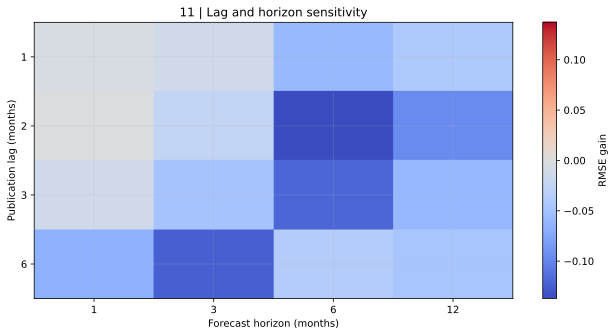

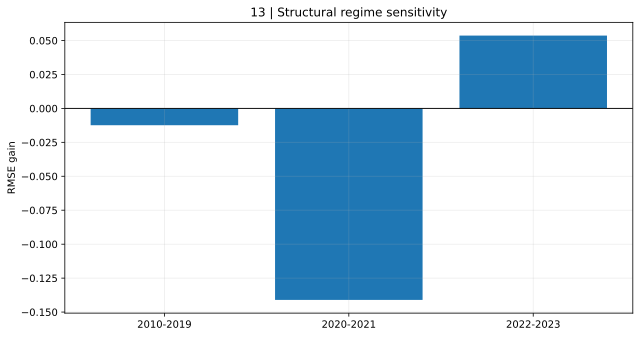

In [22]:
display(SVG(filename=str(ra.FIGURES/'11_horizon_lag.svg')))
display(SVG(filename=str(ra.FIGURES/'13_regime.svg')))

## 12. Bias Audit & Verdict

**Publication/revision:** the 2023-ending redistributed snapshot is not a series of archived monthly vintages. **Target leakage:** a five-month origin-to-training-target availability rule and two-month feature buffer are enforced, but historical revisions remain. **Selection:** broilers and a red-meat-versus-turkey factor were chosen with domain reasoning; this single test is not a registered pre-analysis plan. **Survivorship:** national physical output avoids a surviving-equity-universe problem, but corporate exposures are only contemporary examples. **Multiple testing:** 16 lag/horizon combinations and ablations are descriptive and not used to select the primary. **Costs/market impact:** not measurable because no security return strategy is tested. **Structural breaks:** technology, slaughter mix, and COVID-era supply shifts threaten transportability.

In [23]:
gain=M['observed_rmse_gain_log_pp'];ci=M['bootstrap_gain_ci_95']
print('Primary gain (positive would favor candidate):',round(gain,6))
print('Bootstrap interval:',ci)
print('Placebo exploratory tail:',M['placebo_exploratory_tail_fraction'])
print('Verdict:', 'NEGATIVE incremental macro-factor evidence' if gain<=0 else 'INCONCLUSIVE exploratory gain')
print('No PIT, company fundamental, total-return or investable alpha claim.')

Primary gain (positive would favor candidate): -0.024796
Bootstrap interval: [-0.07869146697147278, 0.02573495468354355]
Placebo exploratory tail: 0.8431568431568431
Verdict: NEGATIVE incremental macro-factor evidence
No PIT, company fundamental, total-return or investable alpha claim.


## 13. Reproduction

From a clean checkout with Python ≥3.10: `python -m pip install -r requirements.txt`, `python run_analysis.py`, `python -m pytest -q tests`, and `jupyter nbconvert --to notebook --execute research.ipynb --output research.executed.ipynb`. The committed notebook is executed and contains inline tables and figures. Reproducing **byte-identical** SVGs may depend on the Matplotlib version; numeric tables and source checksums are the primary reproducibility objects. The repository-level structural gate is `python scripts/validate_studies.py`, executed separately in CI.

In [24]:
files=[p for p in ra.RESULTS.glob('*') if p.is_file()]
figs=list(ra.FIGURES.glob('*.svg'))
print('Result files:',len(files),'| SVG diagnostic figures:',len(figs))
assert len(figs)>=3 and all(f.stat().st_size>1000 for f in figs)
print('Source hash:',hashlib.sha256(ra.RAW.read_bytes()).hexdigest())
print('First 5 computed result files:',[f.name for f in sorted(files)[:5]])

Result files: 9 | SVG diagnostic figures: 13
Source hash: b587c1e758ae43d87fe86fac0efc73da40aaeaf4046eba370f70fced554564a5
First 5 computed result files: ['ablation_checks.csv', 'baseline_scorecard.csv', 'bootstrap_draws.csv', 'lag_horizon_checks.csv', 'oos_predictions.csv']


## 14. Next-Stage Protocol

Before claiming a PIT predictor: (1) acquire monthly NASS/ERS original-release files with their publication dates and revision history, (2) rebuild monthly factor vintages with exact release timestamp, (3) obtain hatchery placements, feed prices and inventories as economic controls, (4) pre-register a new unseen OOS period and multiple-testing correction, (5) map historical chicken sales and margins from **filings available then**, and (6) independently test dividend/split-adjusted total returns with costs, delistings and capacity. Until then, retain a negative retrospective production-only result.

In [25]:
protocol=pd.DataFrame([
 ['Archived release vintages','NOT AVAILABLE','PIT feasibility'],
 ['Historical company segment sales','NOT TESTED','Fundamental transmission'],
 ['Delisting-inclusive total returns','NOT TESTED','Equity alpha'],
 ['Feed and hatchery exogenous controls','NOT TESTED','Mechanism discrimination'],
 ['Pre-registered unseen OOS','NOT TESTED','Multiple-testing discipline']],
 columns=['next_stage_input','status','purpose'])
display(protocol)

,next_stage_input,status,purpose
0,Archived release vintages,NOT AVAILABLE,PIT feasibility
1,Historical company segment sales,NOT TESTED,Fundamental transmission
2,Delisting-inclusive total returns,NOT TESTED,Equity alpha
3,Feed and hatchery exogenous controls,NOT TESTED,Mechanism discrimination
4,Pre-registered unseen OOS,NOT TESTED,Multiple-testing discipline


## 15. Sources & Artifacts

**Empirical source:** `plotnine.data.meat` ([documentation](https://plotnine.org/reference/meat.html)); frozen local CSV checksum is recorded in `results/summary.json`. **Official methodology:** [USDA ERS All Meat Statistics](https://www.ers.usda.gov/data-products/livestock-and-meat-domestic-data/documentation) and [USDA NASS Poultry Slaughter](https://data.nass.usda.gov/Surveys/Guide_to_NASS_Surveys/Poultry_Slaughter/index.php). **Qualitative company mapping:** [Tyson 2023 10-K](https://www.sec.gov/Archives/edgar/data/100493/000010049323000105/tsn-20230930.htm), [Pilgrim's Pride 2023 10-K](https://www.sec.gov/Archives/edgar/data/802481/000080248124000015/ppc-20231231.htm). Complete grades, exact dates, observation periods, vintage caveats and roles are in `data/source_register.csv`. All figures and tables here are computed, not illustrative placeholders.

In [26]:
print('Empirical input:',ra.RAW.relative_to(ra.HERE))
print('Full source register:');display(reg[['id','grade','exact_url','vintage']])
print('Final:',M['status'])
assert not M['pit_verified'] and not M['security_total_returns_tested']

Empirical input: data/raw_plotnine_meat_2023_snapshot.csv
Full source register:


,id,grade,exact_url,vintage
0,S01,B,https://plotnine.org/reference/meat.html,local plotnine 0.15.3 packaged meat.csv SHA256...
1,S02,A,https://www.ers.usda.gov/data-products/livesto...,Current documentation only; NOT the frozen emp...
2,S03,A,https://data.nass.usda.gov/Surveys/Guide_to_NA...,"Release policy, not reconstructed series"
3,S04,A,https://www.sec.gov/Archives/edgar/data/100493...,2023 filing; NOT valid historical exposure for...
4,S05,A,https://www.sec.gov/Archives/edgar/data/802481...,2023 filing; NOT valid historical exposure for...
5,S06,A,https://www.ers.usda.gov/data-products/livesto...,Current 2026 page NOT used as empirical data


Final: REPRODUCED RETROSPECTIVE POULTRY PRODUCTION MACRO PILOT - NOT PIT / NOT EQUITY ALPHA
